# Multi-Fidelity Method Comparison: Shifted Peaks Function
Example is based on the peaks function with a shifted low fidelity function for multi-fidelity purposes

In [19]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging, mfkans
import multi_fidelity_functions

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Introduce the example function

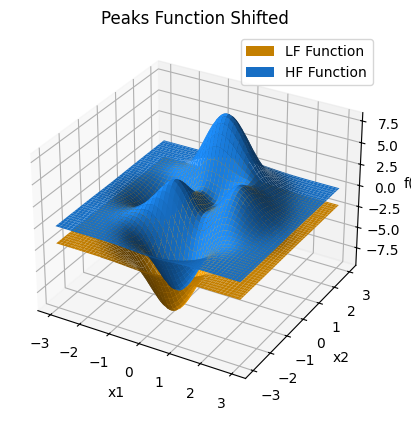

In [20]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.PeaksShifted4()
mf_example.plot_functions(name=mf_example.name)
plt.legend()
plt.grid()
plt.show()

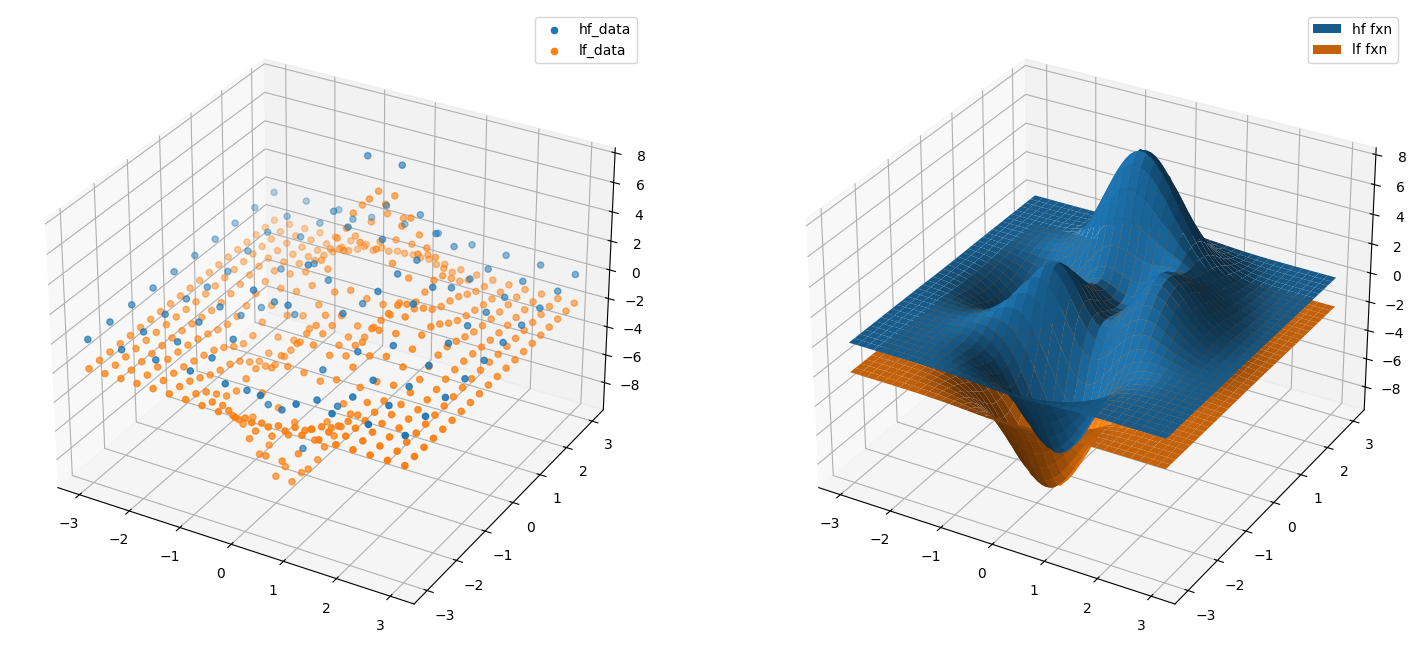

In [21]:
import multi_fidelity_functions as mff
import matplotlib.pyplot as plt
from SurrogateModels import cokriging, model

n_hf = 10
n_lf = 20
n_samp = 75

bounds = mf_example.bounds
x1min = bounds[0][0]
x1max = bounds[0][1]
x2min = bounds[1][0]
x2max = bounds[1][1]

X_hf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_hf)
X_lf = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_lf)
y_hf = mf_example.high_fidelity(X_hf)
y_lf = mf_example.low_fidelity(X_lf)

# take samples for plotting ground truth function
X_test = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_samp)
y_hf_test = mf_example.high_fidelity(X_test)
y_lf_test = mf_example.low_fidelity(X_test)

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(121, projection="3d")

sc = ax.scatter(X_hf[:, 0], X_hf[:, 1],y_hf[:,0], label="hf_data")
sc = ax.scatter(X_lf[:, 0], X_lf[:, 1],y_lf[:,0], label="lf_data")
ax.legend()

#Plot the actual surfaces of the lf and hf functions

X1, X2 = model.Model.generate_grid(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = y_hf_test.reshape(n_samp,n_samp)
y_samp_lf = y_lf_test.reshape(n_samp,n_samp)

ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X1, X2, y_samp_hf,label="hf fxn")
ax.plot_surface(X1, X2, y_samp_lf,label="lf fxn")
ax.legend()

plt.show()

## Multi-Fidelity Neural Network Fit

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

In [40]:
mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf,
    y_lf=y_lf,
    X_lf_test=X_test,
    y_lf_test=y_lf_test,
    X_hf=X_hf,
    y_hf=y_hf,
    X_hf_test=X_test,
    y_hf_test=y_hf_test,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[10, 10, 10],
    epochs_lf=100,
    epochs_mf=1000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.02,
    wd_mf=0.05,
)

Epoch: 0   || Train Error: 0.023222360759973526 || Test Error: 0.020231785252690315

Epoch: 1   || Train Error: 0.01496274396777153 || Test Error: 0.01229491550475359

Epoch: 2   || Train Error: 0.010155895724892616 || Test Error: 0.009739933535456657

Epoch: 3   || Train Error: 0.00874048750847578 || Test Error: 0.008161618374288082

Epoch: 4   || Train Error: 0.007446714676916599 || Test Error: 0.006642945110797882

Epoch: 5   || Train Error: 0.00542842224240303 || Test Error: 0.004927980713546276

Epoch: 6   || Train Error: 0.0041170381009578705 || Test Error: 0.0033958556596189737

Epoch: 7   || Train Error: 0.005057770758867264 || Test Error: 0.00448068929836154

Epoch: 8   || Train Error: 0.003483694279566407 || Test Error: 0.002921368693932891

Epoch: 9   || Train Error: 0.0025553926825523376 || Test Error: 0.0021117962896823883

Epoch: 10   || Train Error: 0.0016853321576490998 || Test Error: 0.0015248649287968874

Epoch: 11   || Train Error: 0.0012807324528694153 || Test Error

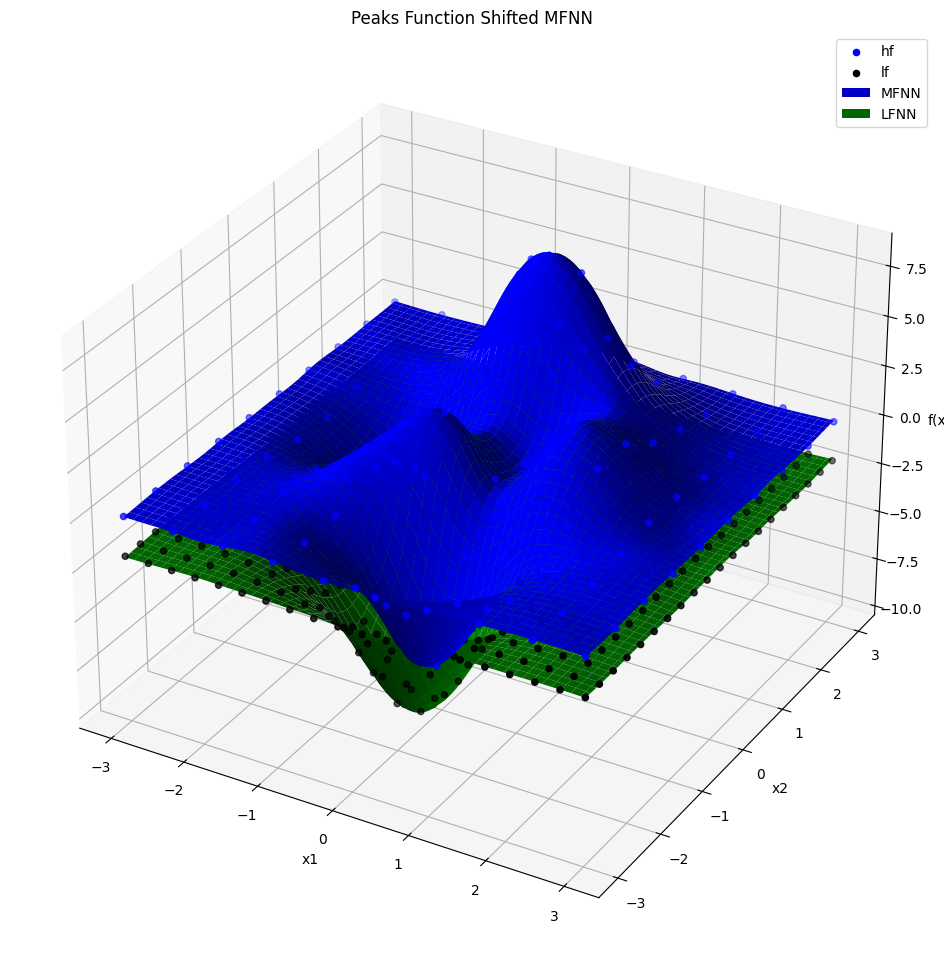

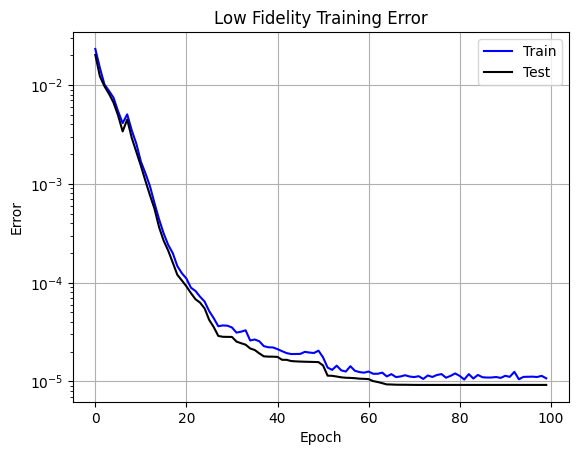

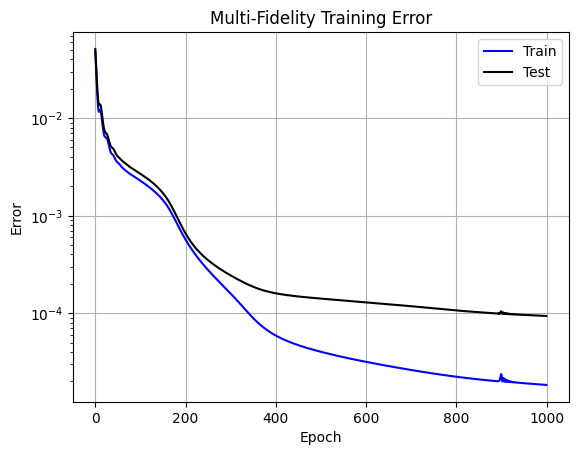

In [41]:
# Plot the results
plot_name = mf_example.name + " MFNN"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = mfnn_model.plot_data(plot_name, ax= ax)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MFNN",
    linestyle="solid",
    ax=ax,
)
ax = mfnn_model.low_fidelity_nn.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="LFNN",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

In [24]:
hfnn_model = mfsnn.MLPNetwork(
    X=X_hf,
    y=y_hf,
    X_test=X_test,
    y_test=y_hf_test,
    hidden_layer_size=[20, 20, 20],
    epochs=50,
    learning_rate=0.001,
    weight_decay=0.000001,
)

Epoch: 0   || Train Error: 0.025486748665571213 || Test Error: 0.025237977504730225

Epoch: 1   || Train Error: 0.024449501186609268 || Test Error: 0.024030914530158043

Epoch: 2   || Train Error: 0.02348770946264267 || Test Error: 0.02288571186363697

Epoch: 3   || Train Error: 0.021236838772892952 || Test Error: 0.020265188068151474

Epoch: 4   || Train Error: 0.01874982751905918 || Test Error: 0.01754673570394516

Epoch: 5   || Train Error: 0.01581469364464283 || Test Error: 0.014676173217594624

Epoch: 6   || Train Error: 0.013515865430235863 || Test Error: 0.01270128134638071

Epoch: 7   || Train Error: 0.011861342005431652 || Test Error: 0.01132403127849102

Epoch: 8   || Train Error: 0.010031257756054401 || Test Error: 0.009738611057400703

Epoch: 9   || Train Error: 0.007949714548885822 || Test Error: 0.007845519110560417

Epoch: 10   || Train Error: 0.005683038849383593 || Test Error: 0.005673638079315424

Epoch: 11   || Train Error: 0.004650895018130541 || Test Error: 0.00469

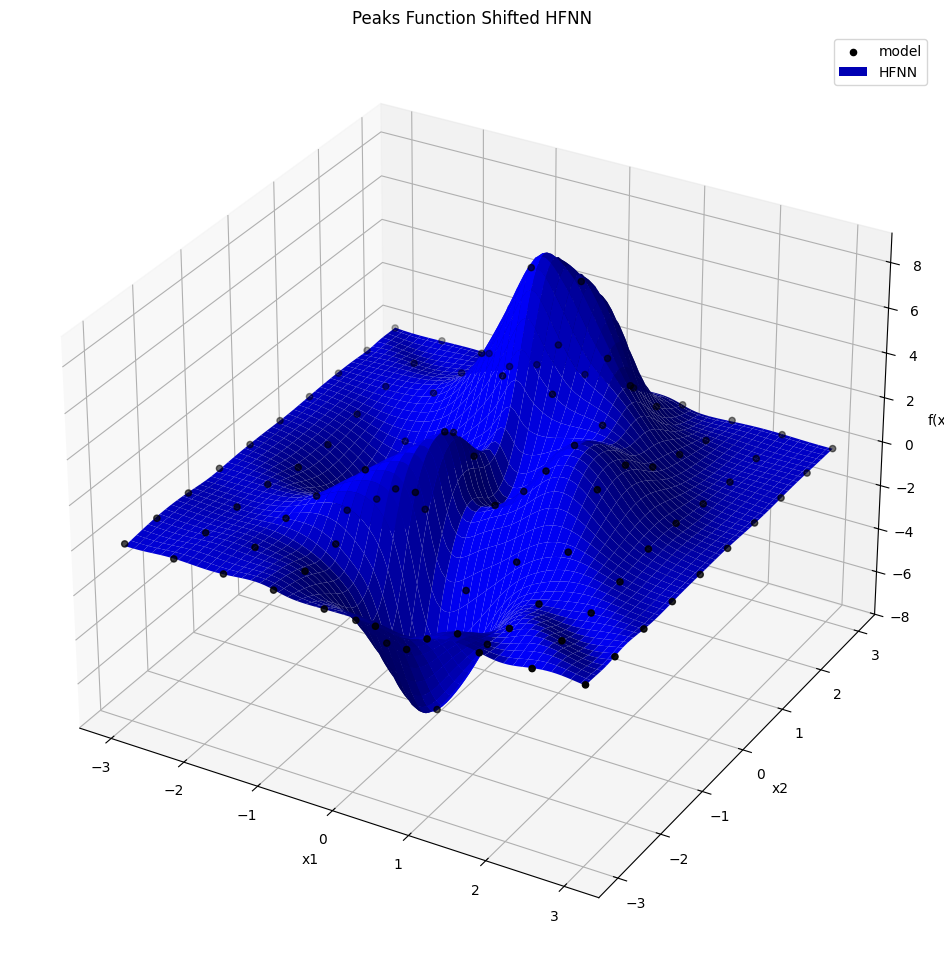

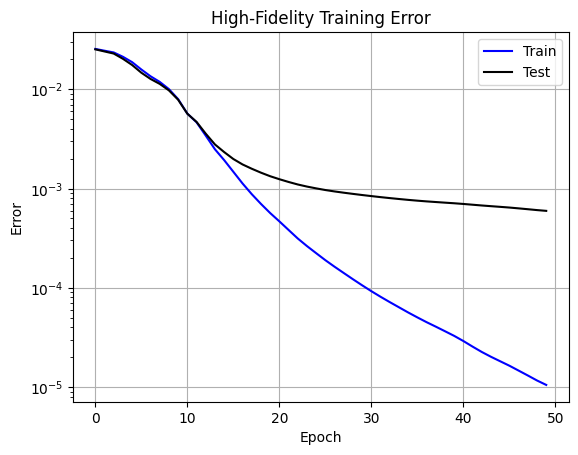

In [25]:
# Plot the results
plot_name = mf_example.name + " HFNN"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = hfnn_model.plot_data(plot_name, ax= ax)
ax = hfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="HFNN",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Plot the model error
hfnn_model.plot_training_error("High-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

## Co-Kriging Function Fit

Utilizes the Co-Kriging function fit outlined in the Forrester 2007 paper.

In [26]:
cokriging_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf, nugget=1e-1)

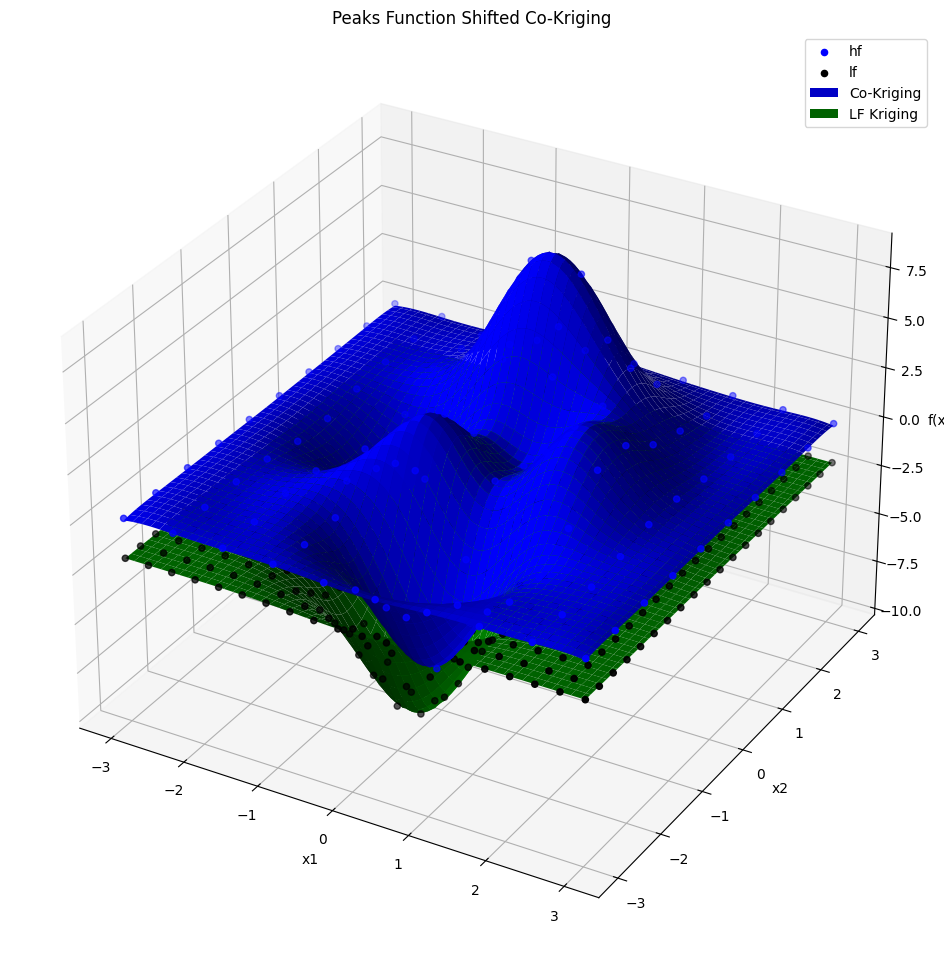

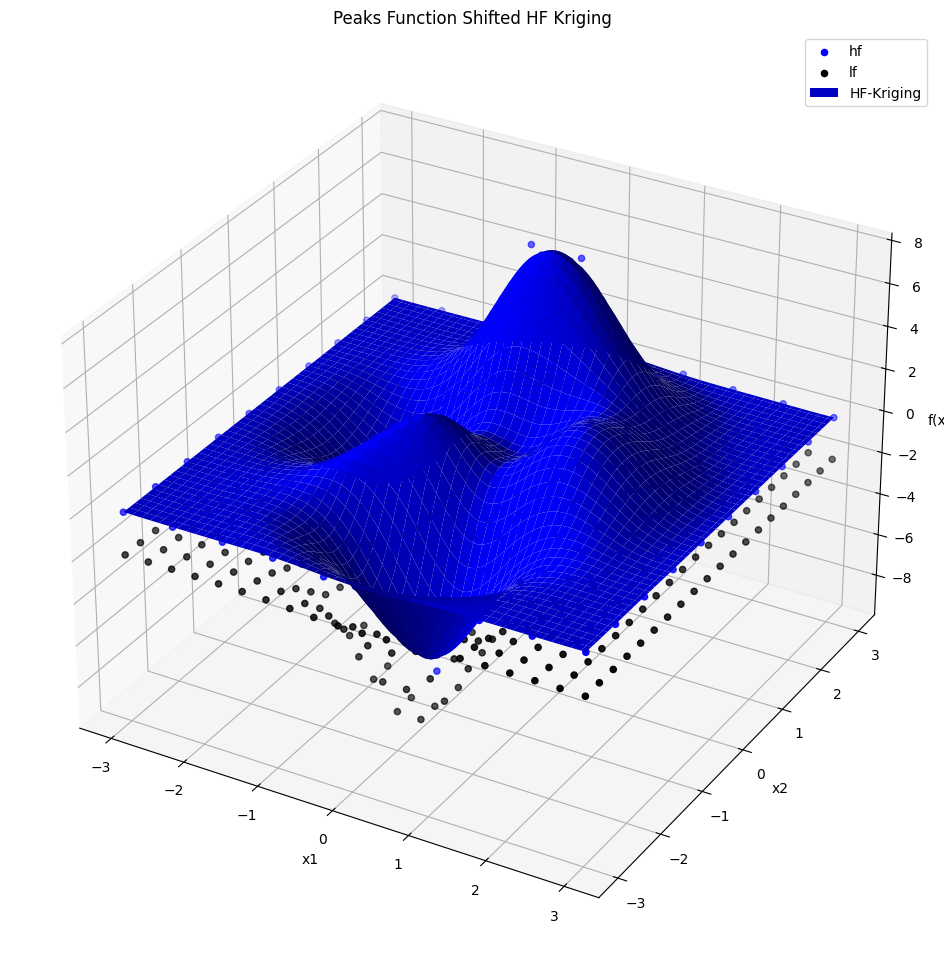

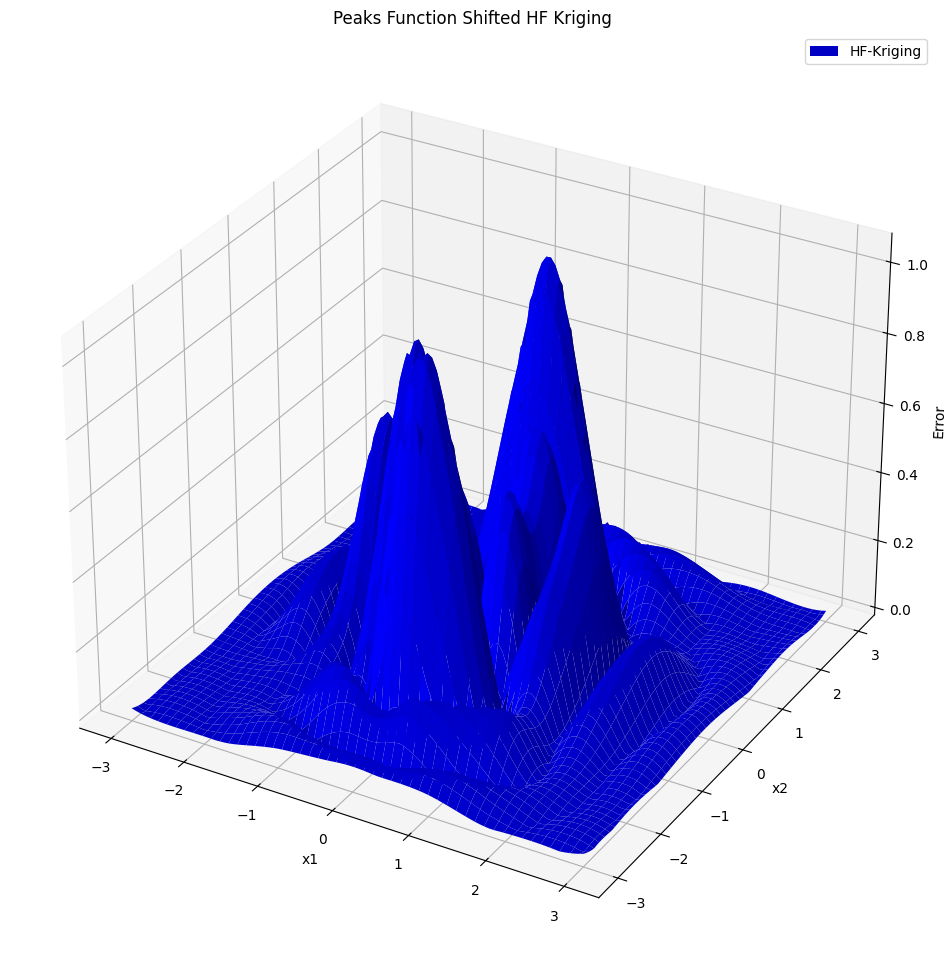

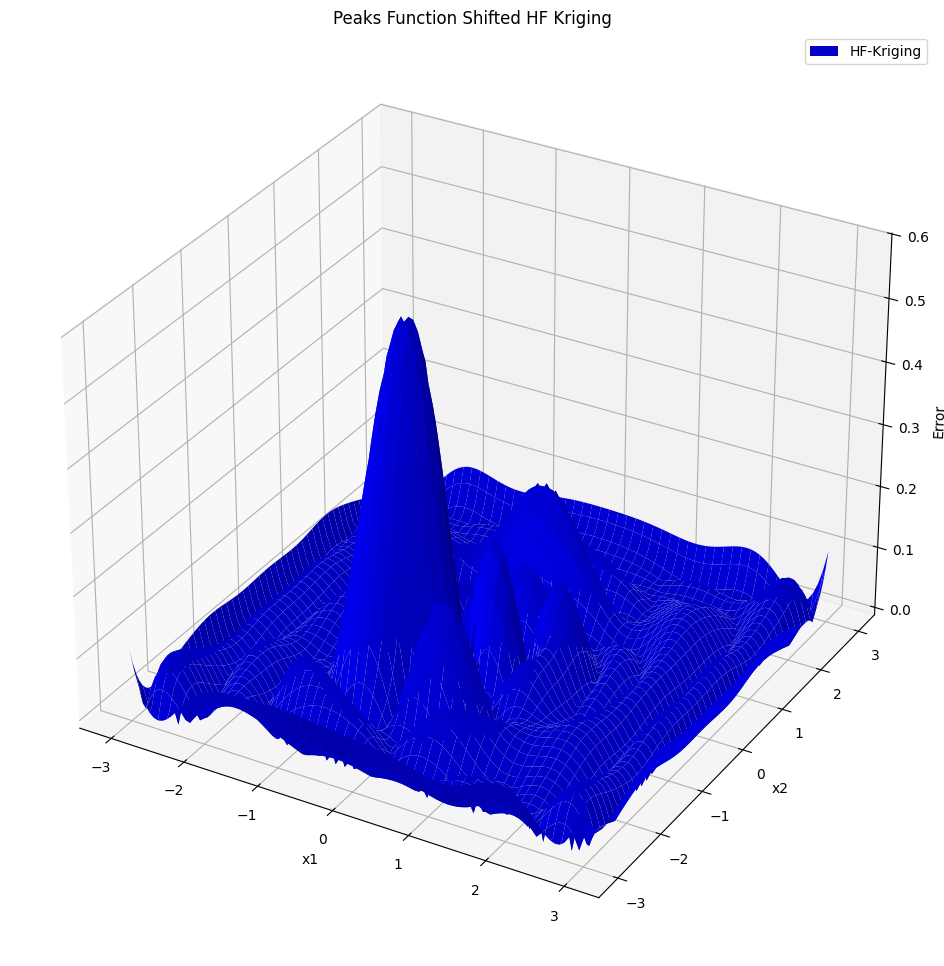

In [27]:
# Plot the results
plot_name = mf_example.name + " Co-Kriging"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = cokriging_model.plot_data(plot_name, ax=ax)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="Co-Kriging",
    linestyle="solid",
    ax=ax,
)
ax = cokriging_model.kriging_lf.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF Kriging",
    color="green",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

plot_name = mf_example.name + " HF Kriging"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = cokriging_model.plot_data(plot_name, ax=ax)
ax = cokriging_model.kriging_hf.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="HF-Kriging",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = cokriging_model.kriging_hf.plot_rms_error(
    mf_example.bounds,
    fxn_truth = mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="HF-Kriging",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    fxn_truth = mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="HF-Kriging",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### MFKAN Model
Sets up a MFKAN model for a 1D dataset

In [28]:
# MFKAN Model for forrester mf example
mfkan_model = mfkans.MFKANModel(
    x_lf=X_lf,
    y_lf=y_lf,
    x_lf_test=X_test,
    y_lf_test=y_lf_test,
    x_hf=X_hf,
    y_hf=y_hf,
    x_hf_test=X_test,
    y_hf_test=y_hf_test,
    spline_order_lf=3,
    spline_order_mf=2,
    hidden_layers_lf=[4, 4],
    hidden_layers_mf=[5, 3],
    grid_lf=[3, 5, 10],
    grid_mf=[2],
    opt_lf="LBFGS",
    opt_mf="LBFGS",
    n_iter_lf=50,
    n_iter_mf=50,
    lr_lf=0.1,
    lr_mf=0.001,
)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.10e-01 | test_loss: 1.10e-01 | reg: 2.83e+01 | : 100%|█| 50/50 [00:32<00:00,  1.52it


saving model version 0.1
saving model version 0.2


| train_loss: 3.39e-02 | test_loss: 3.45e-02 | reg: 2.83e+01 | : 100%|█| 50/50 [00:34<00:00,  1.43it


saving model version 0.3
saving model version 0.4


| train_loss: 8.24e-03 | test_loss: 8.67e-03 | reg: 2.83e+01 | : 100%|█| 50/50 [00:37<00:00,  1.35it


saving model version 0.5
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 3.05e-02 | test_loss: 3.52e-02 | reg: 2.19e+01 | : 100%|█| 50/50 [00:21<00:00,  2.36it

saving model version 0.1


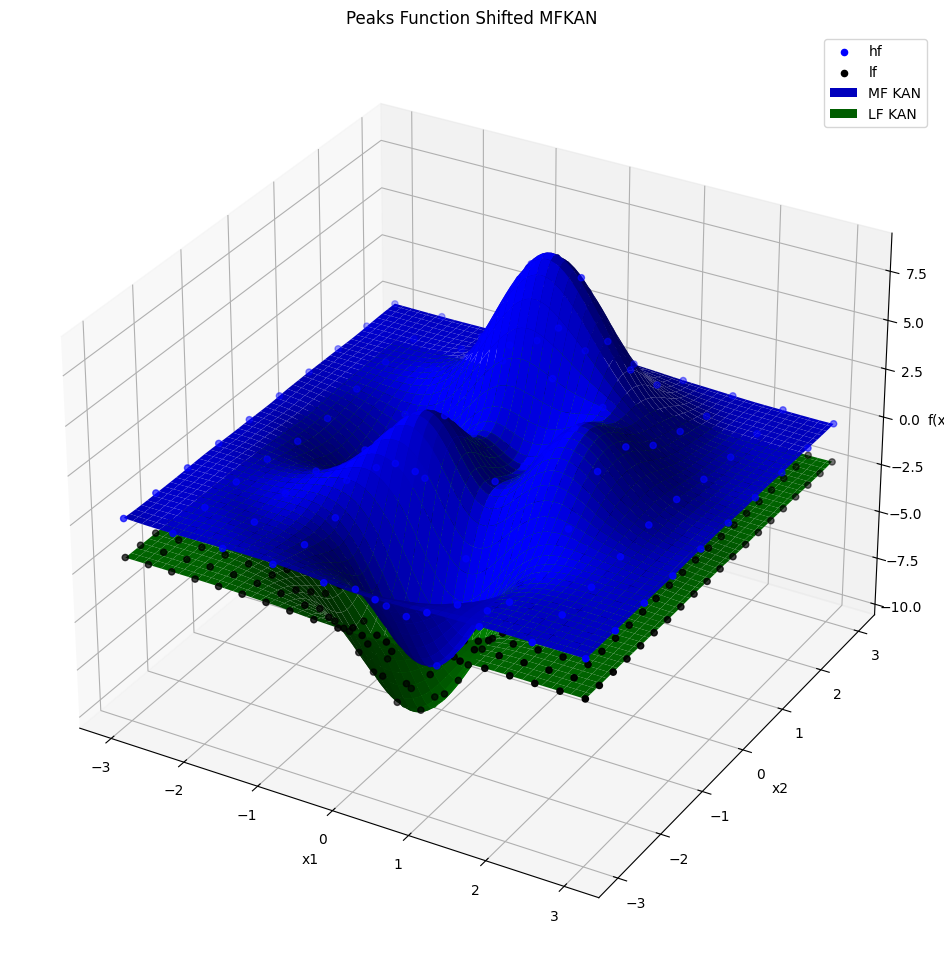

In [29]:
# Plot the results
plot_name = mf_example.name + " MFKAN"

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(111, projection="3d")

ax = mfkan_model.plot_data(plot_name,ax=ax)
ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="solid",
    ax=ax,
)
ax = mfkan_model.lf_kan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF KAN",
    color="green",
    linestyle="solid",
    ax=ax,
)
#ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Model Comparison

Compare the three different methods for their ability to fit the high fidelity function.

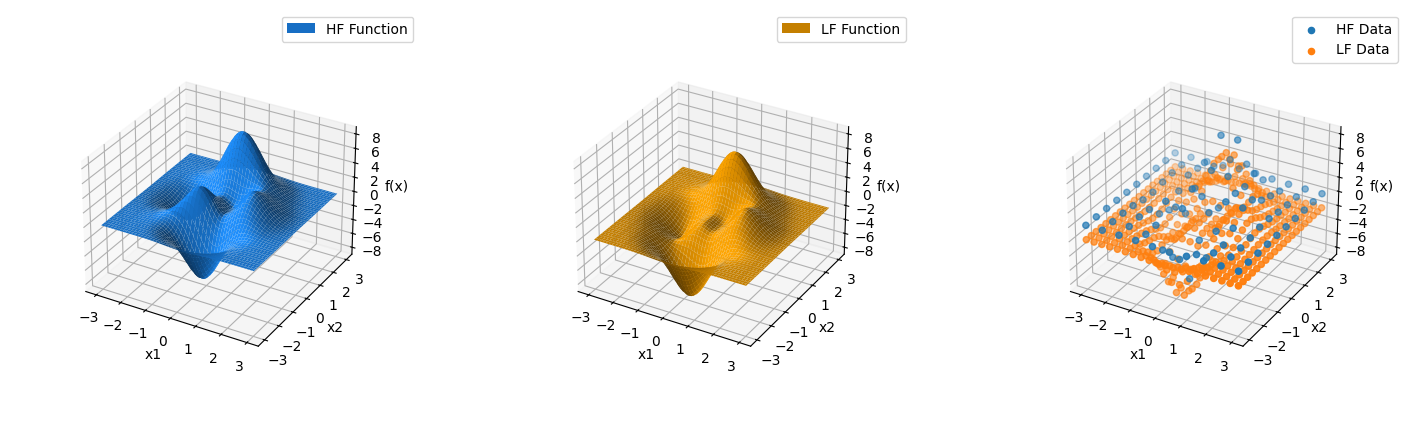

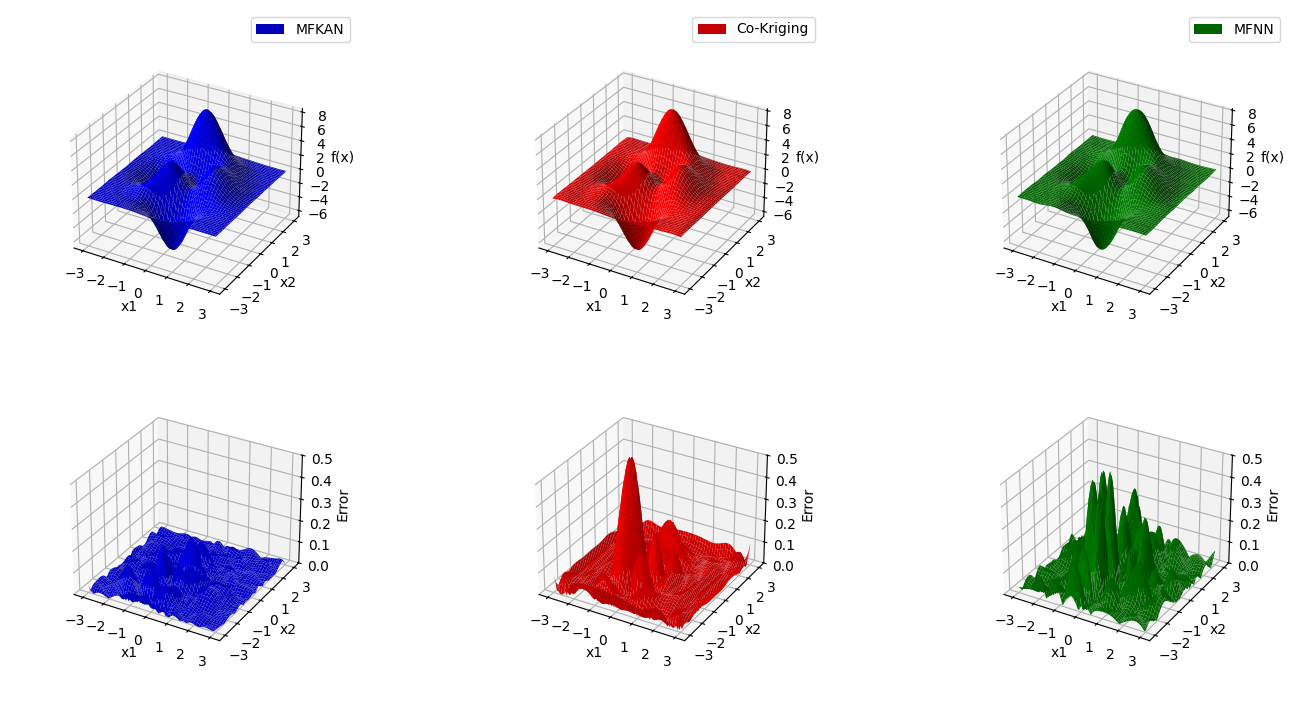

tensor(0.0353)


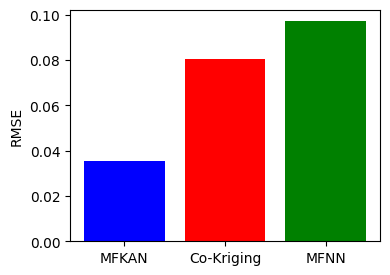

In [51]:
# Set figure size for plots
fig = plt.figure(figsize=(18, 9))

# Plot the models and sample data
ax = fig.add_subplot(131, projection="3d")

# Set zoom to fix stupid matplotlib bug on label clipping
zoom = 0.75

plot_name = ""

ax = mf_example.plot_high_fidelity(name=plot_name, ax=ax)
ax.grid()
ax.legend()
ax.set_box_aspect(None, zoom=zoom)
ax.set_zlim(-9.0, 9.0)

ax = fig.add_subplot(132, projection="3d")

ax = mf_example.plot_low_fidelity(name=plot_name, ax=ax)
ax.grid()
ax.legend()
ax.set_box_aspect(None, zoom=zoom)
ax.set_zlim(-9.0, 9.0)

ax = fig.add_subplot(133, projection="3d")

sc = ax.scatter(X_hf[:, 0], X_hf[:, 1], y_hf[:, 0], label="HF Data")
sc = ax.scatter(X_lf[:, 0], X_lf[:, 1], y_lf[:, 0], label="LF Data")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("f(x)")
ax.grid()
ax.legend()
ax.set_box_aspect(None, zoom=zoom)
ax.set_zlim(-9.0, 9.0)

plot_name = ""
plt.show()


fig = plt.figure(figsize=(18, 9))

# Plot the model fits
ax = fig.add_subplot(231, projection="3d")

ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MFKAN",
    linestyle="dashed",
    ax=ax,
)
ax.grid()
ax.legend()
ax.set_box_aspect(None, zoom=zoom)

ax = fig.add_subplot(232, projection="3d")

ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax.grid()
ax.legend()
ax.set_box_aspect(None, zoom=zoom)

ax = fig.add_subplot(233, projection="3d")

ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax.grid()
ax.legend()
ax.set_box_aspect(None, zoom=zoom)


# Plot the error comparison
ax = fig.add_subplot(234, projection="3d")
plot_name = ""

ax = mfkan_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="MFKAN",
    linestyle="dashed",
    ax=ax,
)
ax.set_zlim(0.0, 0.5)
ax.grid()
ax.set_box_aspect(None, zoom=zoom)

ax = fig.add_subplot(235, projection="3d")
ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax.set_zlim(0.0, 0.5)
ax.grid()
ax.set_box_aspect(None, zoom=zoom)

ax = fig.add_subplot(236, projection="3d")
ax = mfnn_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax.set_zlim(0.0, 0.5)
ax.grid()
ax.set_box_aspect(None, zoom=zoom)
plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

# Plot the error comparison
fig = plt.figure(figsize=(4, 3))
ax = fig.add_subplot()
plot_name = ""
names = ["MFKAN", "Co-Kriging", "MFNN"]
print(mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity))
error = [
    mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
    cokriging_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
    mfnn_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
]
bar_colors = ["blue", "red", "green"]
ax.bar(names, error, color=bar_colors)
ax.set_ylabel("RMSE")
plt.show()

c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


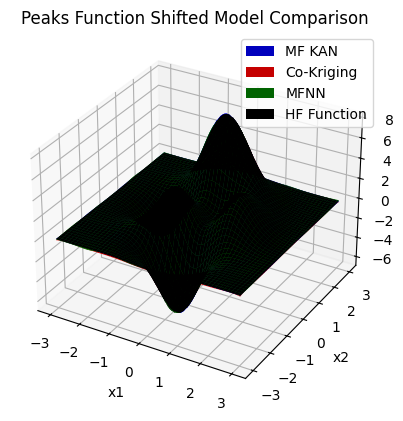

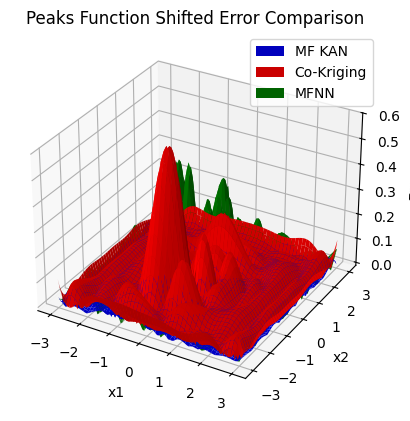

In [45]:
plot_name = mf_example.name + " Model Comparison"

ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax = mf_example.plot_high_fidelity(
    name=plot_name, linestyle="solid", color="black", ax=ax
)
plt.legend()
plt.grid()
plt.show()

plot_name = mf_example.name + " Error Comparison"

ax = mfkan_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
)
ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
plt.legend()
plt.grid()
plt.show()

Min1: (0.22983712050734237,-1.6430498797483437,-6.415309564701443)
Min2: (-1.373680288150577,0.22556806440435778,-3.0072288621984504)
Min3: (0.301909843457509,0.32013148776453215,-0.07057846066367235)
Max1: (-0.0038712685882090654,2.0000000027008893,5.927761914910398)
Max2: (-0.4344797718700957,-0.5648203185337465,3.359924028623179)
Max3: (1.308911878190326,-0.004343715955499162,3.554152272895659)


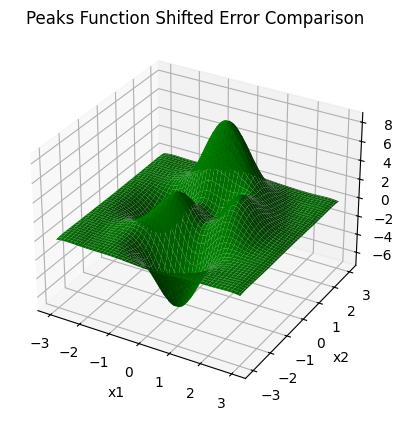

In [46]:
import scipy


def f(x):
    x_in = np.array([x])
    y_out = cokriging_model.evaluate(x_in)
    return y_out


def neg_f(x):
    x_in = np.array([x])
    y_out = cokriging_model.evaluate(x_in)
    return -y_out


x = np.array([0, 0])
f(x)

# find minimum 1
bounds = [(-1, 1), (-3, -1)]
x0 = np.array([0, -2])

res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min1: ({res.x[0]},{res.x[1]},{res.fun})")

# find minimum 2
bounds = [(-3, -1), (-1, 2)]
x0 = np.array([-2, 0])

res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min2: ({res.x[0]},{res.x[1]},{res.fun})")

# find minimum 3
bounds = [(-1, 1), (0, 2)]
x0 = np.array([0, 1])

res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min3: ({res.x[0]},{res.x[1]},{res.fun})")


# find maximum 1
bounds = [(-1, 1), (2, 3)]
x0 = np.array([0, 2.5])

res = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max1: ({res.x[0]},{res.x[1]},{-res.fun})")

# find maximum 2
bounds = [(-1, 0), (-2, 1)]
x0 = np.array([-0.5, 0])

res = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max2: ({res.x[0]},{res.x[1]},{-res.fun})")

# find maximum 3
bounds = [(0, 2), (-1, 1)]
x0 = np.array([1, -0.5])

res = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max3: ({res.x[0]},{res.x[1]},{-res.fun})")

# res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
# print(res.x, res.fun)

ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="Co-Kriging",
    linestyle="dotted",
)
sc = ax.scatter(res.x[0], res.x[1], -res.fun, label="minimum")

plt.show()

Min1: (0.22827887675377898,-1.6255311065892213,-6.551133332621052)
Min2: (-1.3473968611106288,0.20453051062580818,-3.049849402143782)
Min3: (0.29643743366642383,0.32020105567408363,-0.06493586771969173)
Max1: (-0.0028196492686466267,2.0000000027008893,5.85917475713172)
Max2: (-0.46002438340752305,-0.6291936251265102,3.7765809984410277)
Max3: (1.285683280962172,-0.004861260401001825,3.592489917316068)


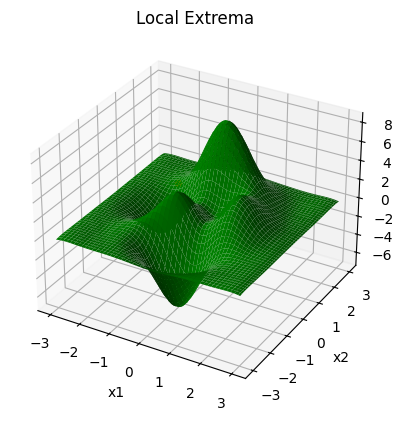

In [47]:
def f(x):
    x_in = np.array([x])
    y_out = mf_example.high_fidelity(x_in)
    return y_out


def neg_f(x):
    x_in = np.array([x])
    y_out = mf_example.high_fidelity(x_in)
    return -y_out

x = np.array([0, 0])
f(x)

# find minimum 1
bounds = [(-1, 1), (-3, -1)]
x0 = np.array([0, -2])

res1 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min1: ({res1.x[0]},{res1.x[1]},{res1.fun})")

# find minimum 2
bounds = [(-3, -1), (-1, 2)]
x0 = np.array([-2, 0])

res2 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min2: ({res2.x[0]},{res2.x[1]},{res2.fun})")

# find minimum 3
bounds = [(-1, 1), (0, 2)]
x0 = np.array([0, 1])

res3 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min3: ({res3.x[0]},{res3.x[1]},{res3.fun})")


# find maximum 1
bounds = [(-1, 1), (2, 3)]
x0 = np.array([0, 2.5])

res4 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max1: ({res4.x[0]},{res4.x[1]},{-res4.fun})")

# find maximum 2
bounds = [(-1, 0), (-2, 1)]
x0 = np.array([-0.5, 0])

res5 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max2: ({res5.x[0]},{res5.x[1]},{-res5.fun})")

# find maximum 3
bounds = [(0, 2), (-1, 1)]
x0 = np.array([1, -0.5])

res6 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max3: ({res6.x[0]},{res6.x[1]},{-res6.fun})")

# res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
# print(res.x, res.fun)
plot_name = "Local Extrema"
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="Co-Kriging",
    linestyle="dotted",
)
sc = ax.scatter(res1.x[0], res1.x[1], -res1.fun, label="minimum", c="orange")

plt.show()

file_name = "Example_ExtremaOut.txt"
with open(file_name, 'w') as file:
    file.write(f"Min1: {res1.x[0]} {res1.x[1]} {res1.fun}\n")
    file.write(f"Min2: {res2.x[0]} {res2.x[1]} {res2.fun}\n")
    file.write(f"Min3: {res3.x[0]} {res3.x[1]} {res3.fun}\n")
    file.write(f"Max1: {res4.x[0]} {res4.x[1]} {-res4.fun}\n")
    file.write(f"Max2: {res5.x[0]} {res5.x[1]} {-res5.fun}\n")
    file.write(f"Max3: {res6.x[0]} {res6.x[1]} {-res6.fun}")

Min1: (0.22983712050734237,-1.6430498797483437,-6.415309564701443)
Min2: (-1.373680288150577,0.22556806440435778,-3.0072288621984504)
Min3: (0.301909843457509,0.32013148776453215,-0.07057846066367235)
Max1: (-0.0038712685882090654,2.0000000027008893,5.927761914910398)
Max2: (-0.4344797718700957,-0.5648203185337465,3.359924028623179)
Max3: (1.308911878190326,-0.004343715955499162,3.554152272895659)


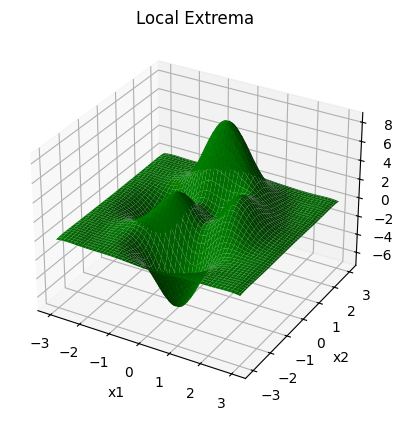

In [48]:
import scipy


def f(x):
    x_in = np.array([x])
    y_out = cokriging_model.evaluate(x_in)
    return y_out


def neg_f(x):
    x_in = np.array([x])
    y_out = cokriging_model.evaluate(x_in)
    return -y_out


x = np.array([0, 0])
f(x)

# find minimum 1
bounds = [(-1, 1), (-3, -1)]
x0 = np.array([0, -2])

res1 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min1: ({res1.x[0]},{res1.x[1]},{res1.fun})")

# find minimum 2
bounds = [(-3, -1), (-1, 2)]
x0 = np.array([-2, 0])

res2 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min2: ({res2.x[0]},{res2.x[1]},{res2.fun})")

# find minimum 3
bounds = [(-1, 1), (0, 2)]
x0 = np.array([0, 1])

res3 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min3: ({res3.x[0]},{res3.x[1]},{res3.fun})")


# find maximum 1
bounds = [(-1, 1), (2, 3)]
x0 = np.array([0, 2.5])

res4 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max1: ({res4.x[0]},{res4.x[1]},{-res4.fun})")

# find maximum 2
bounds = [(-1, 0), (-2, 1)]
x0 = np.array([-0.5, 0])

res5 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max2: ({res5.x[0]},{res5.x[1]},{-res5.fun})")

# find maximum 3
bounds = [(0, 2), (-1, 1)]
x0 = np.array([1, -0.5])

res6 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max3: ({res6.x[0]},{res6.x[1]},{-res6.fun})")

# res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
# print(res.x, res.fun)
plot_name = "Local Extrema"
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="Co-Kriging",
    linestyle="dotted",
)
sc = ax.scatter(res1.x[0], res1.x[1], -res1.fun, label="minimum", c="orange")

plt.show()

file_name = "CoKriging_ExtremaOut.txt"
with open(file_name, 'w') as file:
    file.write(f"Min1: {res1.x[0]} {res1.x[1]} {res1.fun}\n")
    file.write(f"Min2: {res2.x[0]} {res2.x[1]} {res2.fun}\n")
    file.write(f"Min3: {res3.x[0]} {res3.x[1]} {res3.fun}\n")
    file.write(f"Max1: {res4.x[0]} {res4.x[1]} {-res4.fun}\n")
    file.write(f"Max2: {res5.x[0]} {res5.x[1]} {-res5.fun}\n")
    file.write(f"Max3: {res6.x[0]} {res6.x[1]} {-res6.fun}\n")

Min1: (0.17370936029595785,-1.6353858128594898,-6.626727104187012)
Min2: (-1.3588861487945363,0.1895277241630501,-2.919875144958496)
Min3: (0.33022855251760636,0.26363344204563555,-0.073883056640625)
Max1: (-0.0007317353586581615,2.0000003204678185,5.966724395751953)
Max2: (-0.34204120662750614,-0.5684519370968117,3.6355457305908203)
Max3: (1.255156332257068,0.039024816011332425,3.2895631790161133)


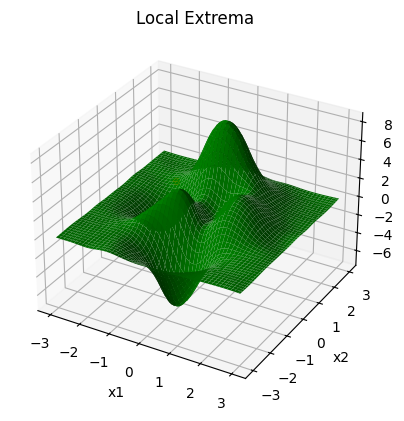

In [49]:
import scipy


def f(x):
    x_in = np.array([x],dtype=np.float32)
    y_out = mfnn_model.evaluate(x_in)
    return y_out


def neg_f(x):
    x_in = np.array([x],dtype=np.float32)
    y_out = mfnn_model.evaluate(x_in)
    return -y_out


x = np.array([0.0, 0.0],dtype=np.float32)
f(x)

# find minimum 1
bounds = [(-1.0, 1.0), (-3.0, -1.0)]
bounds = np.array(bounds,dtype=np.float32)
x0 = np.array([0.0, -2.0],dtype=np.float32)

res1 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min1: ({res1.x[0]},{res1.x[1]},{res1.fun})")

# find minimum 2
bounds = [(-3.0, -1.0), (-1.0, 2.0)]
x0 = np.array([-2.0, 0.0],dtype=np.float32)

res2 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min2: ({res2.x[0]},{res2.x[1]},{res2.fun})")

# find minimum 3
bounds = [(-1.0, 1.0), (0.0, 2.0)]
x0 = np.array([0.0, 1.0],dtype=np.float32)

res3 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min3: ({res3.x[0]},{res3.x[1]},{res3.fun})")


# find maximum 1
bounds = [(-1.0, 1.0), (2.0, 3.0)]
x0 = np.array([0.0, 2.5],dtype=np.float32)

res4 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max1: ({res4.x[0]},{res4.x[1]},{-res4.fun})")

# find maximum 2
bounds = [(-1.0, 0.0), (-2.0, 1.0)]
x0 = np.array([-0.5, 0.0],dtype=np.float32)

res5 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max2: ({res5.x[0]},{res5.x[1]},{-res5.fun})")

# find maximum 3
bounds = [(0.0, 2.0), (-1.0, 1.0)]
x0 = np.array([1, -0.5],dtype=np.float32)

res6 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max3: ({res6.x[0]},{res6.x[1]},{-res6.fun})")

# res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
# print(res.x, res.fun)
plot_name = "Local Extrema"
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="Co-Kriging",
    linestyle="dotted",
)
sc = ax.scatter(res1.x[0], res1.x[1], -res1.fun, label="minimum", c="orange")

plt.show()

file_name = "NN_ExtremaOut.txt"
with open(file_name, 'w') as file:
    file.write(f"Min1: {res1.x[0]} {res1.x[1]} {res1.fun}\n")
    file.write(f"Min2: {res2.x[0]} {res2.x[1]} {res2.fun}\n")
    file.write(f"Min3: {res3.x[0]} {res3.x[1]} {res3.fun}\n")
    file.write(f"Max1: {res4.x[0]} {res4.x[1]} {-res4.fun}\n")
    file.write(f"Max2: {res5.x[0]} {res5.x[1]} {-res5.fun}\n")
    file.write(f"Max3: {res6.x[0]} {res6.x[1]} {-res6.fun}\n")

c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\kan\MultKAN.py:813: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\ReduceOps.cpp:1823.)
  self.subnode_actscale.append(torch.std(x, dim=0).detach())
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\kan\MultKAN.py:823: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\aten\src\ATen\native\ReduceOps.cpp:1823.)
  input_range = torch.std(preacts, dim=0) + 0.1
c:\Users\troyz\GitProjects\SurrogateModeling2\.venv\lib\site-packages\kan\MultKAN.py:824: UserWarning: std(): degrees of freedom is <= 0. Correction shou

Min1: (0.23679745212869918,-1.6361946311808389,-6.568953990936279)
Min2: (-1.3548263897830761,0.20318623131182514,-3.0278804302215576)
Min3: (0.28446865866588184,0.2908394944280813,-0.2053612470626831)
Max1: (-0.0035356038766768505,2.000000535828079,5.844209671020508)
Max2: (-0.43855383594735986,-0.6098207966514818,3.6962549686431885)
Max3: (1.2794421199950867,0.00740843728490742,3.57511043548584)


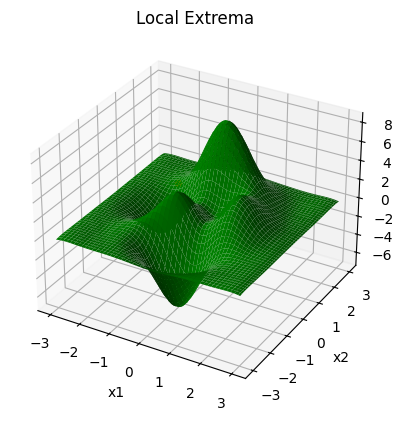

In [50]:
import scipy


def f(x):
    x_in = np.array([x],dtype=np.float32)
    y_out = mfkan_model.evaluate(x_in)
    return y_out


def neg_f(x):
    x_in = np.array([x],dtype=np.float32)
    y_out = mfkan_model.evaluate(x_in)
    return -y_out


x = np.array([0.0, 0.0],dtype=np.float32)

# find minimum 1
bounds = [(-1.0, 1.0), (-3.0, -1.0)]
bounds = np.array(bounds,dtype=np.float32)
x0 = np.array([0.0, -2.0],dtype=np.float32)

res1 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min1: ({res1.x[0]},{res1.x[1]},{res1.fun})")

# find minimum 2
bounds = [(-3.0, -1.0), (-1.0, 2.0)]
x0 = np.array([-2.0, 0.0],dtype=np.float32)

res2 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min2: ({res2.x[0]},{res2.x[1]},{res2.fun})")

# find minimum 3
bounds = [(-1.0, 1.0), (0.0, 2.0)]
x0 = np.array([0.0, 1.0],dtype=np.float32)

res3 = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
print(f"Min3: ({res3.x[0]},{res3.x[1]},{res3.fun})")


# find maximum 1
bounds = [(-1.0, 1.0), (2.0, 3.0)]
x0 = np.array([0.0, 2.5],dtype=np.float32)

res4 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max1: ({res4.x[0]},{res4.x[1]},{-res4.fun})")

# find maximum 2
bounds = [(-1.0, 0.0), (-2.0, 1.0)]
x0 = np.array([-0.5, 0.0],dtype=np.float32)

res5 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max2: ({res5.x[0]},{res5.x[1]},{-res5.fun})")

# find maximum 3
bounds = [(0.0, 2.0), (-1.0, 1.0)]
x0 = np.array([1, -0.5],dtype=np.float32)

res6 = scipy.optimize.minimize(neg_f, x0, method="Powell", bounds=bounds)
print(f"Max3: ({res6.x[0]},{res6.x[1]},{-res6.fun})")

# res = scipy.optimize.minimize(f, x0, method="Powell", bounds=bounds)
# print(res.x, res.fun)
plot_name = "Local Extrema"
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="Co-Kriging",
    linestyle="dotted",
)
sc = ax.scatter(res1.x[0], res1.x[1], -res1.fun, label="minimum", c="orange")

plt.show()

file_name = "KAN_ExtremaOut.txt"
with open(file_name, 'w') as file:
    file.write(f"Min1: {res1.x[0]} {res1.x[1]} {res1.fun}\n")
    file.write(f"Min2: {res2.x[0]} {res2.x[1]} {res2.fun}\n")
    file.write(f"Min3: {res3.x[0]} {res3.x[1]} {res3.fun}\n")
    file.write(f"Max1: {res4.x[0]} {res4.x[1]} {-res4.fun}\n")
    file.write(f"Max2: {res5.x[0]} {res5.x[1]} {-res5.fun}\n")
    file.write(f"Max3: {res6.x[0]} {res6.x[1]} {-res6.fun}\n")